In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

c:\Users\ankan\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.4' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
c:\Users\ankan\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


1. Load Dataset

In [2]:
df=pd.read_csv(r"C:\Users\ankan\Desktop\LabmentixPR\Real Estate Investment Advisor\india_housing_prices.csv")
df

,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,...,Age_of_Property,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status
0,1,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.76,0.10,1990,...,35,10,3,High,No,No,"Playground, Gym, Garden, Pool, Clubhouse",West,Owner,Ready_to_Move
1,2,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.52,0.08,2008,...,17,8,1,Low,No,Yes,"Playground, Clubhouse, Pool, Gym, Garden",North,Builder,Under_Construction
2,3,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.79,0.05,1997,...,28,9,8,Low,Yes,No,"Clubhouse, Pool, Playground, Gym",South,Broker,Ready_to_Move
3,4,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,300.29,0.11,1991,...,34,5,7,High,Yes,Yes,"Playground, Clubhouse, Gym, Pool, Garden",North,Builder,Ready_to_Move
4,5,Rajasthan,Jaipur,Locality_466,Villa,4,4823,182.90,0.04,2002,...,23,4,9,Low,No,Yes,"Playground, Garden, Gym, Pool, Clubhouse",East,Builder,Ready_to_Move
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
249995,249996,Gujarat,Ahmedabad,Locality_187,Independent House,5,1995,274.75,0.14,1995,...,30,8,6,Low,No,No,"Playground, Garden, Gym, Clubhouse, Pool",East,Broker,Under_Construction
249996,249997,Tamil Nadu,Chennai,Locality_348,Apartment,1,2293,13.40,0.01,2013,...,12,8,10,Low,No,No,Playground,South,Broker,Ready_to_Move
249997,249998,Telangana,Warangal,Locality_225,Villa,4,2910,236.94,0.08,2003,...,22,10,4,High,Yes,Yes,Playground,South,Builder,Under_Construction
249998,249999,Odisha,Cuttack,Locality_138,Villa,1,1149,141.66,0.12,2007,...,18,3,7,Low,Yes,Yes,"Playground, Gym, Pool",South,Owner,Ready_to_Move


2. Basic Data Understanding

In [40]:
print('Shape of dataset:',df.shape)
df.info()

Shape of dataset: (250000, 27)
<class 'pandas.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 27 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   ID                              250000 non-null  int64  
 1   State                           250000 non-null  str    
 2   City                            250000 non-null  str    
 3   Locality                        250000 non-null  str    
 4   Property_Type                   250000 non-null  str    
 5   BHK                             250000 non-null  int64  
 6   Size_in_SqFt                    250000 non-null  int64  
 7   Price_in_Lakhs                  250000 non-null  float64
 8   Price_per_SqFt                  250000 non-null  float64
 9   Year_Built                      250000 non-null  int64  
 10  Furnished_Status                250000 non-null  str    
 11  Floor_No                        250000 non-null  int64  
 

In [5]:
# Check missing values and duplicate rows
print("Missing values:\n", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values:
 ID                                0
State                             0
City                              0
Locality                          0
Property_Type                     0
BHK                               0
Size_in_SqFt                      0
Price_in_Lakhs                    0
Price_per_SqFt                    0
Year_Built                        0
Furnished_Status                  0
Floor_No                          0
Total_Floors                      0
Age_of_Property                   0
Nearby_Schools                    0
Nearby_Hospitals                  0
Public_Transport_Accessibility    0
Parking_Space                     0
Security                          0
Amenities                         0
Facing                            0
Owner_Type                        0
Availability_Status               0
dtype: int64
Duplicate rows: 0


In [ ]:
# check the unique value
cols =df[['State','City','Locality','Property_Type','Public_Transport_Accessibility','Facing','Owner_Type','Availability_Status']]
for col in cols:
    for col in cols.columns:
        print(f"\n{col}: {df[col].unique()}")


State: <ArrowStringArray>
[    'Tamil Nadu',    'Maharashtra',         'Punjab',      'Rajasthan',
    'West Bengal',   'Chhattisgarh',          'Delhi',      'Jharkhand',
      'Telangana',      'Karnataka',  'Uttar Pradesh',          'Assam',
    'Uttarakhand',          'Bihar',        'Gujarat',        'Haryana',
 'Andhra Pradesh', 'Madhya Pradesh',         'Kerala',         'Odisha']
Length: 20, dtype: str

City: <ArrowStringArray>
[       'Chennai',           'Pune',       'Ludhiana',        'Jodhpur',
         'Jaipur',       'Durgapur',     'Coimbatore',       'Bilaspur',
      'New Delhi',         'Ranchi',       'Warangal',      'Bangalore',
         'Nagpur',        'Lucknow',        'Silchar',       'Dehradun',
          'Noida',           'Gaya',     'Jamshedpur',      'Ahmedabad',
      'Hyderabad',      'Faridabad',       'Amritsar',        'Kolkata',
         'Dwarka', 'Vishakhapatnam',         'Bhopal',         'Indore',
       'Haridwar',         'Mysore',          'P

In [7]:
# Check important numeric columns
numeric_check = [
    "BHK", "Size_in_SqFt", "Price_in_Lakhs",
    "Price_per_SqFt", "Year_Built",
    "Age_of_Property"]

print(df[numeric_check].describe())
print("Non-positive property sizes:",
      (df["Size_in_SqFt"] <= 0).sum())
print("Non-positive prices:",
      (df["Price_in_Lakhs"] <= 0).sum())

                 BHK   Size_in_SqFt  Price_in_Lakhs  Price_per_SqFt  \
count  250000.000000  250000.000000   250000.000000   250000.000000   
mean        2.999396    2749.813216      254.586854        0.130597   
std         1.415521    1300.606954      141.349921        0.130747   
min         1.000000     500.000000       10.000000        0.000000   
25%         2.000000    1623.000000      132.550000        0.050000   
50%         3.000000    2747.000000      253.870000        0.090000   
75%         4.000000    3874.000000      376.880000        0.160000   
max         5.000000    5000.000000      500.000000        0.990000   

          Year_Built  Age_of_Property  
count  250000.000000    250000.000000  
mean     2006.520012        18.479988  
std         9.808575         9.808575  
min      1990.000000         2.000000  
25%      1998.000000        10.000000  
50%      2007.000000        18.000000  
75%      2015.000000        27.000000  
max      2023.000000        35.000000  


In [ ]:
# check the skew value
df.skew(numeric_only=True)

ID                  0.000000
BHK                 0.000543
Size_in_SqFt        0.000796
Price_in_Lakhs      0.008206
Price_per_SqFt      2.318668
Year_Built         -0.000167
Floor_No            0.005311
Total_Floors       -0.000666
Age_of_Property     0.000167
Nearby_Schools     -0.001258
Nearby_Hospitals    0.001099
dtype: float64

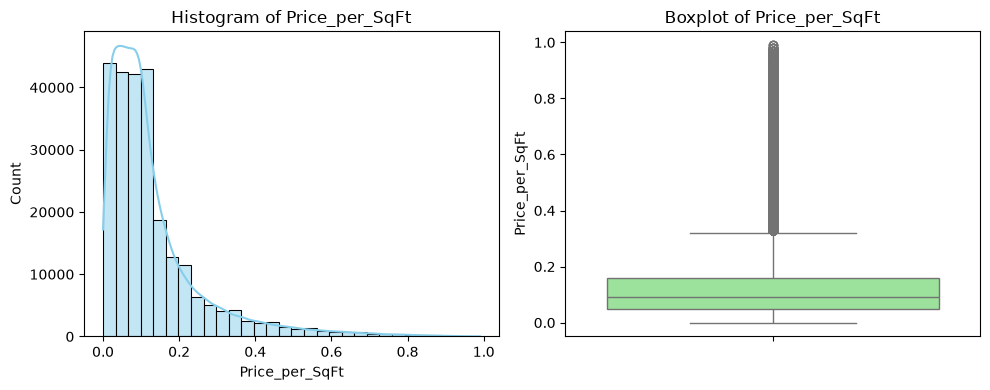

In [9]:
# Histogram
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.histplot(df['Price_per_SqFt'], kde=True, bins=30, ax=axes[0], color="skyblue")
axes[0].set_title(f"Histogram of Price_per_SqFt")

# Boxplot
sns.boxplot(df['Price_per_SqFt'], ax=axes[1], color="lightgreen")
axes[1].set_title(f"Boxplot of Price_per_SqFt")

plt.tight_layout()
plt.show()

I skipped the data cleaning step, as no missing or duplicate values ​​were found.

3. Exploratory Data Analysis (EDA)

1–5: Price & Size Analysis


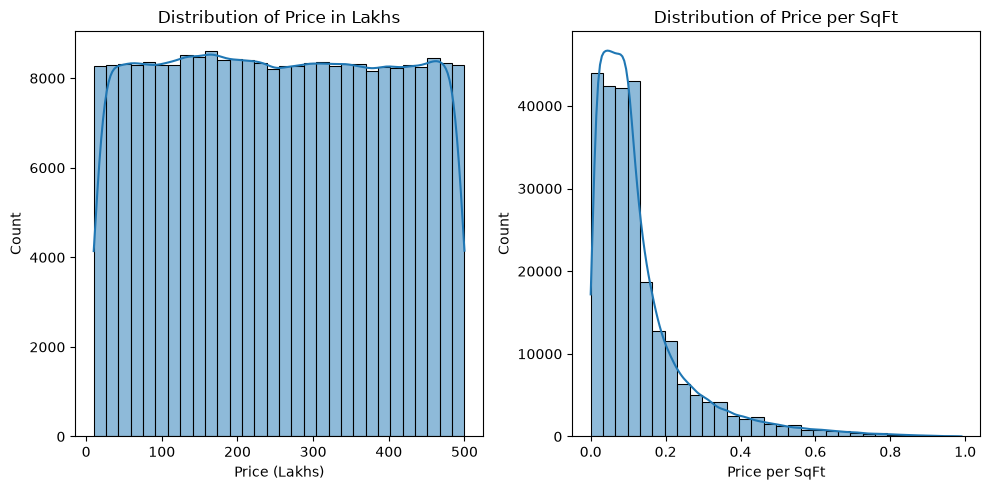

In [10]:
# 1. What is the distribution of property prices?
fig, axes = plt.subplots(1,2,figsize=(10,5))
sns.histplot(df['Price_in_Lakhs'],ax=axes[0],kde=True,bins=30)
sns.histplot(df['Price_per_SqFt'],ax=axes[1],kde=True,bins=30)
axes[0].set_title("Distribution of Price in Lakhs")
axes[1].set_title("Distribution of Price per SqFt")
axes[0].set_xlabel("Price (Lakhs)")
axes[1].set_xlabel("Price per SqFt")
plt.tight_layout()
plt.show()

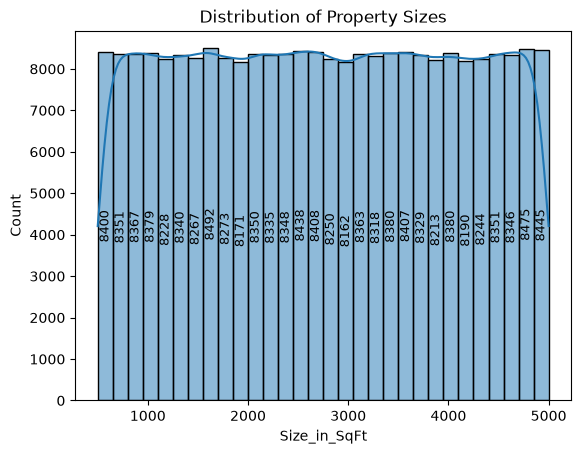

In [11]:
# 2. What is the distribution of property sizes?
sns.histplot(df['Size_in_SqFt'],kde=True,bins=30)
plt.title("Distribution of Property Sizes")
for p in plt.gca().patches:
    plt.gca().annotate(
        str(int(p.get_height())),
        (p.get_x() + p.get_width()/2., p.get_height()/2),  # middle of bar
        ha='center', va='center', fontsize=9, color='black',
        rotation=90)  # rotate text
    
plt.show()

In [12]:
# 3. How does price per SqFt vary by property type?
grouped = df.groupby('Property_Type')['Price_per_SqFt'].mean().reset_index()
print(grouped)

       Property_Type  Price_per_SqFt
0          Apartment        0.130493
1  Independent House        0.131023
2              Villa        0.130276


Correlation between Size_in_SqFt and Price_in_Lakhs: -0.002528546792538916


<Axes: xlabel='Size_in_SqFt', ylabel='Price_in_Lakhs'>

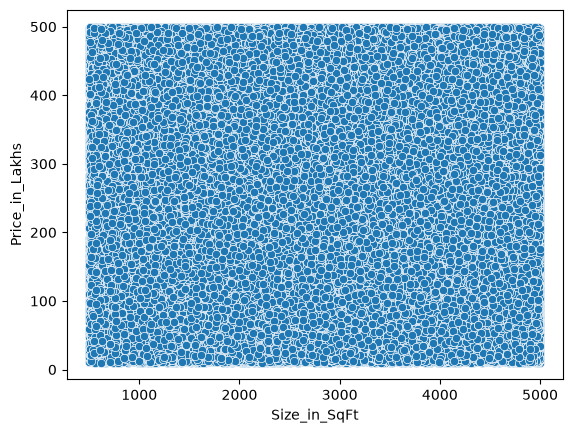

In [13]:
# 4. Is there a relationship between property size and price?
print("Correlation between Size_in_SqFt and Price_in_Lakhs:", df['Size_in_SqFt'].corr(df['Price_in_Lakhs']))
df[['Size_in_SqFt','Price_in_Lakhs']].corr()
sns.scatterplot(x='Size_in_SqFt', y='Price_in_Lakhs', data=df)

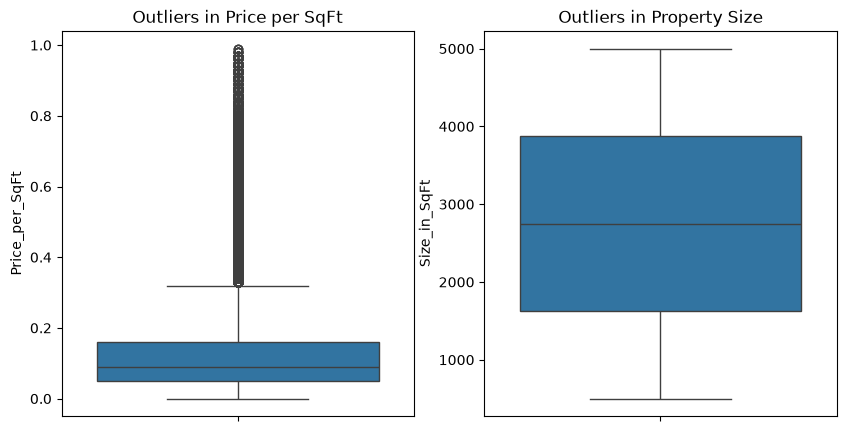

In [14]:
# 5. Are there any outliers in price per sq ft or property size?
fig,axes=plt.subplots(1,2,figsize=(10,5))
sns.boxplot(df['Price_per_SqFt'],ax=axes[0])
sns.boxplot(df['Size_in_SqFt'],ax=axes[1])
axes[0].set_title("Outliers in Price per SqFt")
axes[1].set_title("Outliers in Property Size")
plt.show()

6–10: Location-based Analysis

In [15]:
# 6.What is the average price per sq ft by state?
df.groupby('State')['Price_per_SqFt'].mean().reset_index()

,State,Price_per_SqFt
0,Andhra Pradesh,0.132037
1,Assam,0.130819
2,Bihar,0.130513
3,Chhattisgarh,0.130243
4,Delhi,0.129477
5,Gujarat,0.130995
6,Haryana,0.130692
7,Jharkhand,0.129754
8,Karnataka,0.132538
9,Kerala,0.129849


In [16]:
# 7. What is the average property price by city?
df.groupby('City')[['Price_in_Lakhs', 'Price_per_SqFt']].mean().reset_index()


,City,Price_in_Lakhs,Price_per_SqFt
0,Ahmedabad,253.586827,0.128223
1,Amritsar,252.429802,0.129331
2,Bangalore,258.456639,0.131429
3,Bhopal,256.498896,0.129572
4,Bhubaneswar,254.902173,0.131343
5,Bilaspur,251.879267,0.129301
6,Chennai,256.830172,0.131629
7,Coimbatore,256.504745,0.131117
8,Cuttack,250.786672,0.129306
9,Dehradun,256.890115,0.130047


In [17]:
# 8. What is the median age of properties by locality?
df.groupby('Locality')['Age_of_Property'].median().reset_index()

,Locality,Age_of_Property
0,Locality_1,20.0
1,Locality_10,17.0
2,Locality_100,19.0
3,Locality_101,19.0
4,Locality_102,19.0
...,...,...
495,Locality_95,19.0
496,Locality_96,19.0
497,Locality_97,18.0
498,Locality_98,18.0


BHK                1     2     3     4     5
City                                        
Ahmedabad       1264  1267  1272  1258  1350
Amritsar        1284  1239  1234  1224  1240
Bangalore        839   823   802   833   847
Bhopal          1238  1235  1255  1259  1297
Bhubaneswar     1236  1293  1299  1217  1278
Bilaspur        1210  1252  1275  1268  1258
Chennai         1263  1232  1183  1257  1233
Coimbatore      1236  1301  1317  1345  1262
Cuttack         1320  1292  1301  1236  1209
Dehradun        1238  1297  1225  1248  1226
Durgapur        1311  1259  1287  1260  1270
Dwarka          1295  1211  1248  1216  1276
Faridabad       1202  1231  1261  1214  1261
Gaya            1356  1259  1146  1179  1230
Gurgaon         1241  1221  1239  1232  1212
Guwahati        1240  1158  1272  1188  1234
Haridwar        1233  1290  1230  1223  1291
Hyderabad       1190  1312  1256  1271  1244
Indore          1264  1213  1218  1245  1227
Jaipur          1228  1262  1237  1277  1227
Jamshedpur

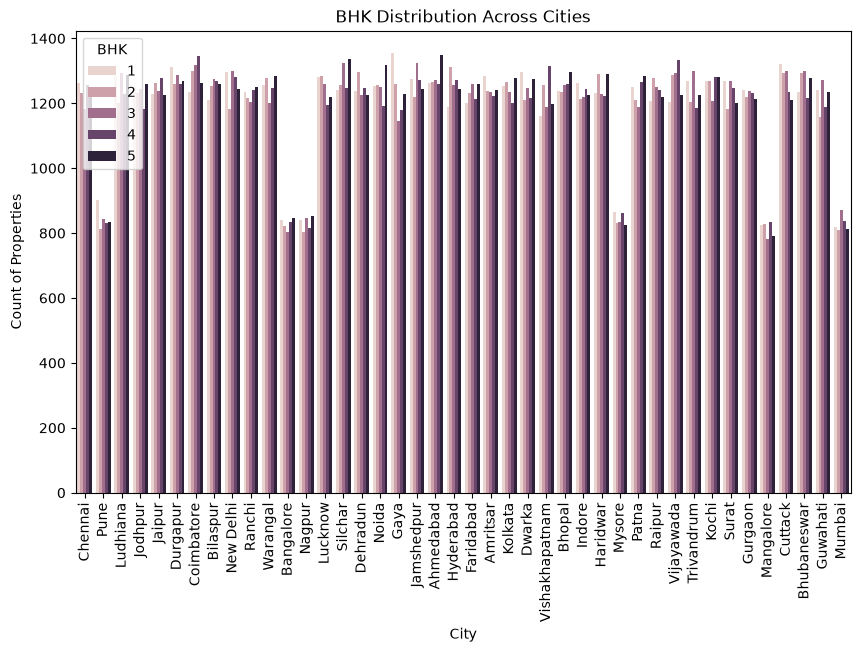

In [18]:
# 9. How is BHK distributed across cities?
print(pd.pivot_table(df, index='City', columns='BHK', values='Price_in_Lakhs', aggfunc='count', fill_value=0))

# vizually
plt.figure(figsize=(10,6))
sns.countplot(x='City', hue='BHK', data=df)
plt.title("BHK Distribution Across Cities")
plt.xlabel("City")
plt.ylabel("Count of Properties")
plt.legend(title="BHK")
plt.xticks(rotation=90)
plt.show()

Index(['Locality_395', 'Locality_366', 'Locality_497', 'Locality_360',
       'Locality_203'],
      dtype='str', name='Locality')


<Axes: xlabel='Year_Built', ylabel='Price_in_Lakhs'>

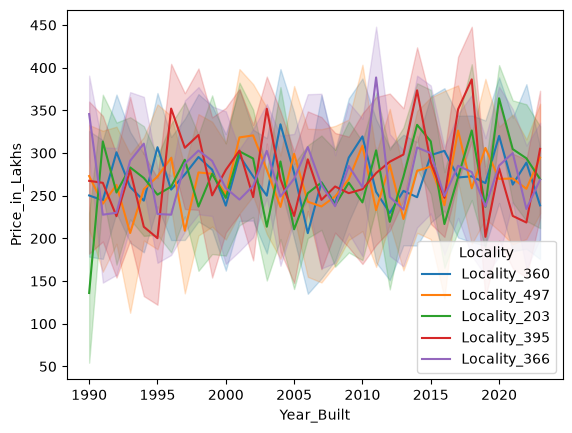

In [19]:
# 10. What are the price trends for the top 5 most expensive localities?
top_localities = df.groupby('Locality')['Price_in_Lakhs'].mean().nlargest(5).index
print(top_localities)
# vizually shown with lineplot
sns.lineplot(x='Year_Built', y='Price_in_Lakhs', hue='Locality',data=df[df['Locality'].isin(top_localities)])

11–15: Feature Relationship & Correlation

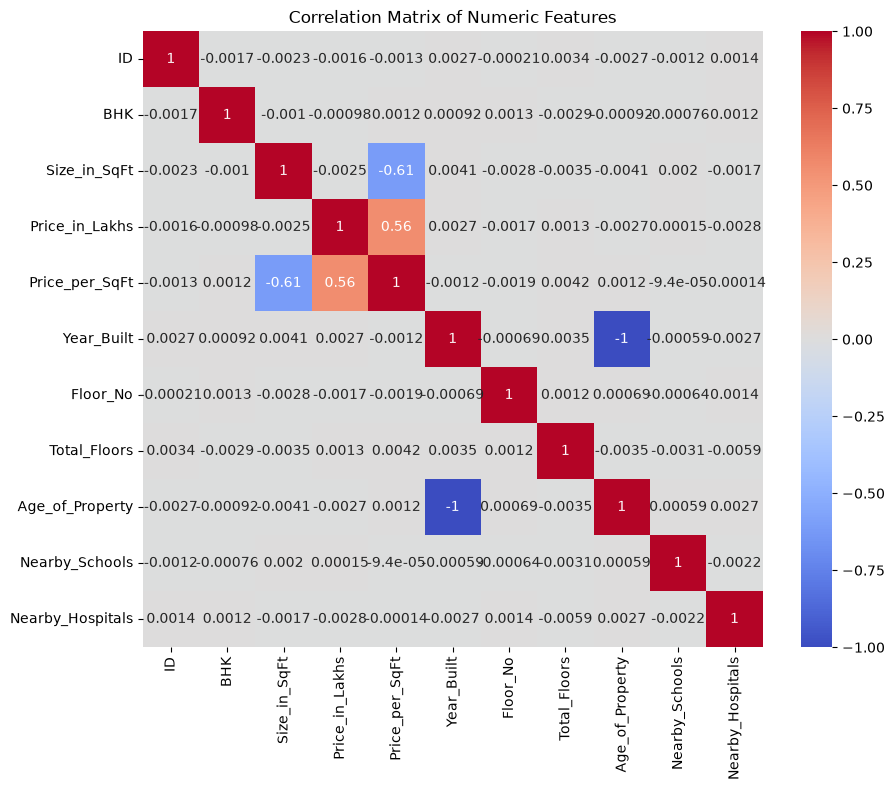

In [20]:
# 11.How are numeric features correlated with each other?
numeric_df = df.select_dtypes(include=[np.number])
correlation_matrix = numeric_df.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0)
plt.title('Correlation Matrix of Numeric Features')
plt.show()

In [21]:
# 12.How do nearby schools relate to price per sq ft?
school_analysis = (df.groupby("Nearby_Schools")
      .agg(Mean_Price_per_SqFt=("Price_per_SqFt", "mean"),
          Property_Count=("Price_per_SqFt", "size")).reset_index())

display(school_analysis)

,Nearby_Schools,Mean_Price_per_SqFt,Property_Count
0,1,0.130644,25360
1,2,0.131271,24851
2,3,0.130708,25045
3,4,0.128892,24739
4,5,0.129943,25023
5,6,0.132939,24824
6,7,0.130440,24808
7,8,0.129559,25290
8,9,0.131041,24823
9,10,0.130548,25237


In [22]:
# 13.How do nearby hospitals relate to price per sq ft?
Hospital_analysis = (df.groupby('Nearby_Hospitals')
      .agg(Mean_Price_per_SqFt=("Price_per_SqFt", "mean"),
          Property_Count=("Price_per_SqFt", "size")).reset_index())

display(Hospital_analysis)

,Nearby_Hospitals,Mean_Price_per_SqFt,Property_Count
0,1,0.130208,25075
1,2,0.130275,24960
2,3,0.132350,24834
3,4,0.129981,25168
4,5,0.129179,25102
5,6,0.130076,25082
6,7,0.132600,24887
7,8,0.131172,24891
8,9,0.130824,25014
9,10,0.129338,24987


F_onewayResult(statistic=0.4963134098548385, pvalue=0.608771416230758)


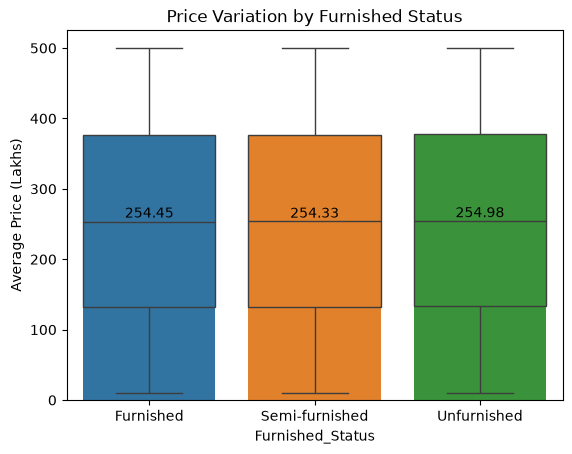

In [23]:
# 14.How does price vary by furnished status?
df.groupby('Furnished_Status')['Price_in_Lakhs'].mean()
from scipy.stats import f_oneway
groups = [df[df['Furnished_Status']==cat]['Price_in_Lakhs'].dropna()
          for cat in df['Furnished_Status'].unique()]
f_oneway(*groups)
print(f_oneway(*groups))

# visually shown with barplot and boxplot
summary = df.groupby('Furnished_Status')['Price_in_Lakhs'].mean().reset_index()
palette = {"Furnished": "#1f77b4","Semi-furnished": "#ff7f0e","Unfurnished": "#2ca02c"}
sns.barplot(data=summary,x="Furnished_Status",y="Price_in_Lakhs",hue="Furnished_Status",palette=palette,legend=False)
sns.boxplot(data=df, x='Furnished_Status', y='Price_in_Lakhs',hue='Furnished_Status',palette=palette, legend=False)
for i, value in enumerate(summary['Price_in_Lakhs']):
    plt.text(i, value, f'{value:.2f}', ha='center', va='bottom')

plt.ylabel('Average Price (Lakhs)')
plt.title('Price Variation by Furnished Status')
plt.show()

- F-statistic = 0.4963
- p-value = 0.6088

Since the p-value is much greater than 0.05, there is no statistically significant difference in property prices across furnished statuses (Furnished, Semi-Furnished, Unfurnished).

**Conclusion:** Furnishing status does not appear to influence property price in this dataset.

F_onewayResult(statistic=1.140048910673234, pvalue=0.33126966194306207)


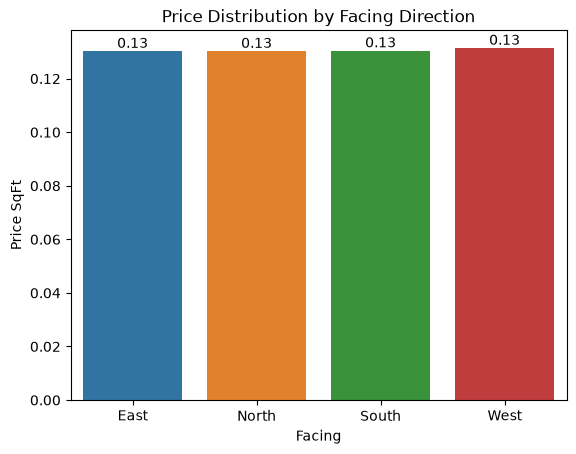

In [24]:
#15.How does price per sq ft vary by property facing direction?
df.groupby('Facing')['Price_per_SqFt'].mean()
groups = [df[df['Facing']==cat]['Price_per_SqFt'].dropna()
          for cat in df['Facing'].unique()]
f_oneway(*groups)
print(f_oneway(*groups))

summary = df.groupby('Facing')['Price_per_SqFt'].mean().reset_index()
sns.barplot(data=summary,x="Facing",y="Price_per_SqFt",hue="Facing",legend=False)
plt.title('Price Distribution by Facing Direction')
for i, value in enumerate(summary['Price_per_SqFt']):
    plt.text(i, value, f'{value:.2f}', ha='center', va='bottom')

plt.ylabel('Price SqFt')
plt.show()

- F-statistic = 1.1400
- p-value = 0.3313

the p-value is greater than 0.05, so there is no statistically significant difference in price per square foot across different facing directions (North, South, East, West, etc.).

**Conclusion:** The direction a property faces does not have a measurable effect on price per SqFt in this dataset.

16–20: Investment / Amenities / Ownership Analysis

  Owner_Type      Property_Type  Count
0     Broker          Apartment  27786
1     Broker  Independent House  27733
2     Broker              Villa  27960
3    Builder          Apartment  27529
4    Builder  Independent House  27792
5    Builder              Villa  27932
6      Owner          Apartment  27641
7      Owner  Independent House  27775
8      Owner              Villa  27852


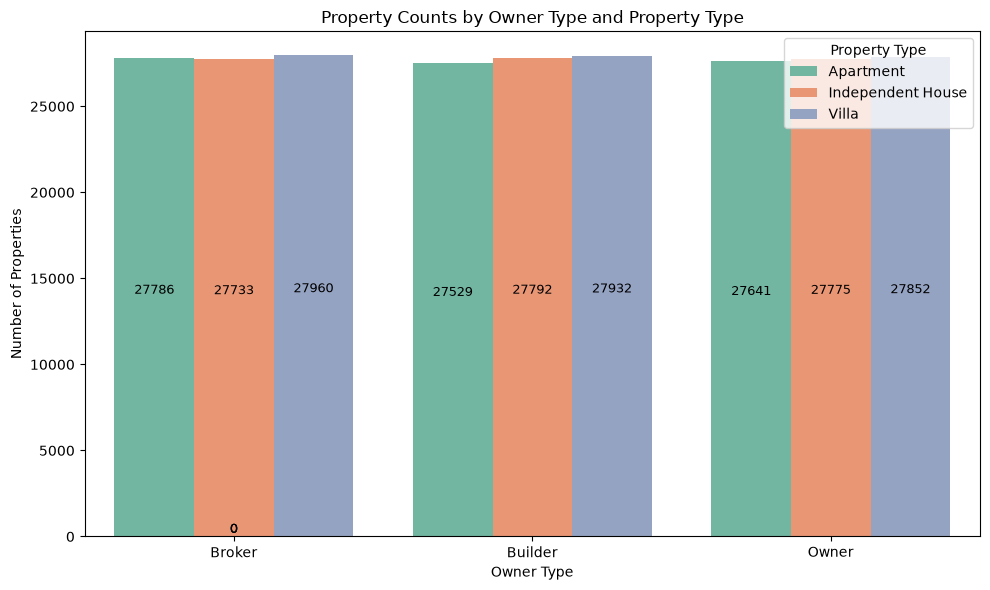

In [25]:
# 16.How many properties belong to each owner type?
summary = df.groupby(['Owner_Type', 'Property_Type']).size().reset_index(name='Count')
print(summary)
plt.figure(figsize=(10,6))
ax = sns.barplot(data=summary, x='Owner_Type', y='Count', hue='Property_Type', palette="Set2")
plt.title("Property Counts by Owner Type and Property Type")
plt.xlabel("Owner Type")
plt.ylabel("Number of Properties")
plt.legend(title="Property Type")
for p in ax.patches:
    ax.annotate(
        format(int(p.get_height()), ),
        (p.get_x() + p.get_width()/2., p.get_height()/2),
        ha='center', va='center',
        fontsize=9, color='black', xytext=(0, 5),
        textcoords='offset points')
plt.tight_layout()
plt.show()

  Availability_Status   Count
0  Under_Construction  125035
1       Ready_to_Move  124965


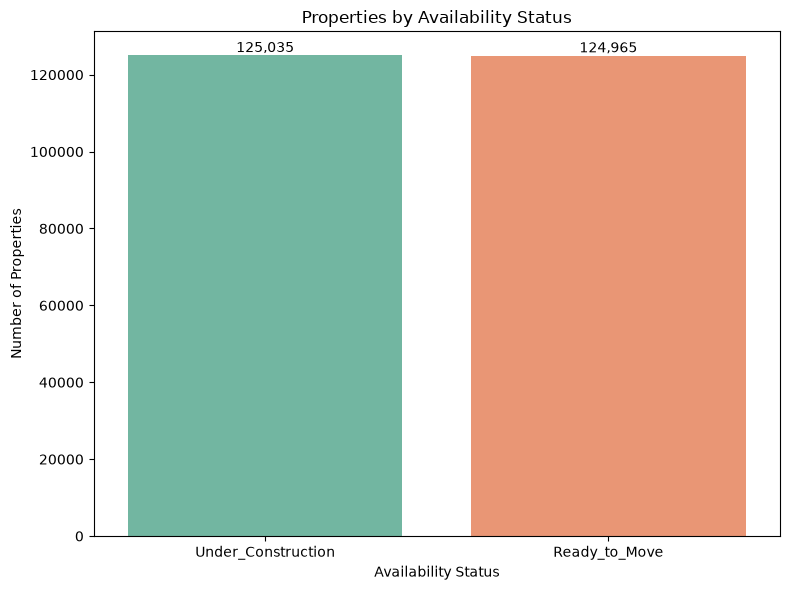

In [26]:
# 17.How many properties are available under each availability status?
summary = df['Availability_Status'].value_counts().reset_index()
summary.columns = ['Availability_Status','Count']
print(summary)
plt.figure(figsize=(8,6))
ax = sns.barplot(data=summary, x='Availability_Status', y='Count', palette="Set2")

plt.title("Properties by Availability Status")
plt.xlabel("Availability Status")
plt.ylabel("Number of Properties")

# Add value labels in the middle of each bar
for p in ax.patches:
    ax.annotate(
        format(int(p.get_height()), ','),
        (p.get_x() + p.get_width()/2., p.get_height()),
        ha='center', va='center', fontsize=10, color='black', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

In [27]:
# 18.Does parking space affect property price?
from scipy.stats import ttest_ind

with_parking = df[df['Parking_Space'] == 'Yes']['Price_in_Lakhs'].dropna()
without_parking = df[df['Parking_Space'] == 'No']['Price_in_Lakhs'].dropna()

t_stat, p_value = ttest_ind(with_parking, without_parking, equal_var=False)

print('t-statistic:', t_stat)
print('p-value:', p_value)

t-statistic: 0.5591134105959178
p-value: 0.5760848237819809


- t-statistic: 0.559
- p-value: 0.576
- Significance level: 0.05
- Because 0.576 > 0.05, fail to reject the null hypothesis.

 **Conlusion:**
An independent two-sample t-test was conducted to compare property prices for homes with and without parking spaces. The test produced a t-statistic of 0.559 and a p-value of 0.576. Since the p-value is greater than 0.05, the result is not statistically significant. Therefore, we fail to reject the null hypothesis and conclude that there is no significant difference in property prices based on parking availability in this dataset. Although parking may appear to affect individual property prices, the observed difference is not strong enough to establish a meaningful relationship statistically.

F-statistic: 0.30429429786342194
p-value: 0.8752621737809132


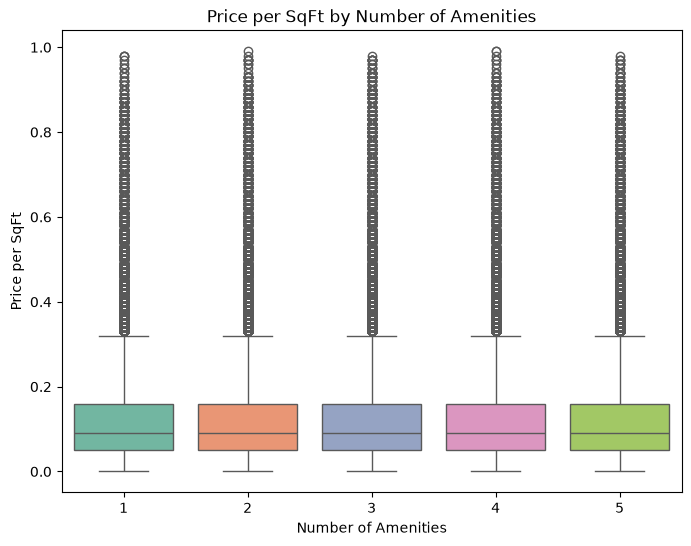

In [28]:
# 19.How do amenities affect price per sq ft?
# checking if the number of amenities has a significant effect on price per sq ft using ANOVA
from scipy.stats import f_oneway
df['Amenity_Count'] = df['Amenities'].apply(lambda x: len(str(x).split(',')))
df.groupby('Amenity_Count')['Price_per_SqFt'].mean()
groups = [df[df['Amenity_Count']==count]['Price_per_SqFt'].dropna()
          for count in df['Amenity_Count'].unique()]
if len(groups) >= 2 and all(len(g) > 0 for g in groups):
    f_stat, p_val = f_oneway(*groups)
    print("F-statistic:", f_stat)
    print("p-value:", p_val)

# Visualization of Price per SqFt by Number of Amenities
plt.figure(figsize=(8,6))
sns.boxplot(x='Amenity_Count', y='Price_per_SqFt', data=df, palette="Set2")
plt.title("Price per SqFt by Number of Amenities")
plt.xlabel("Number of Amenities")
plt.ylabel("Price per SqFt")
plt.show()

- F-statistic: 0.713
- p-value: 0.582
- Because 0.582 > 0.05, fail to reject the null hypothesis.

**Conclusion:**“The one-way ANOVA test shows no statistically significant difference in property price per square foot across different amenity counts (F = 0.71, p = 0.58). This indicates that the number of amenities does not have a measurable effect on property price per square foot in this dataset.”

F-statistic: 0.42679048732593816 p-value: 0.6526007414222464


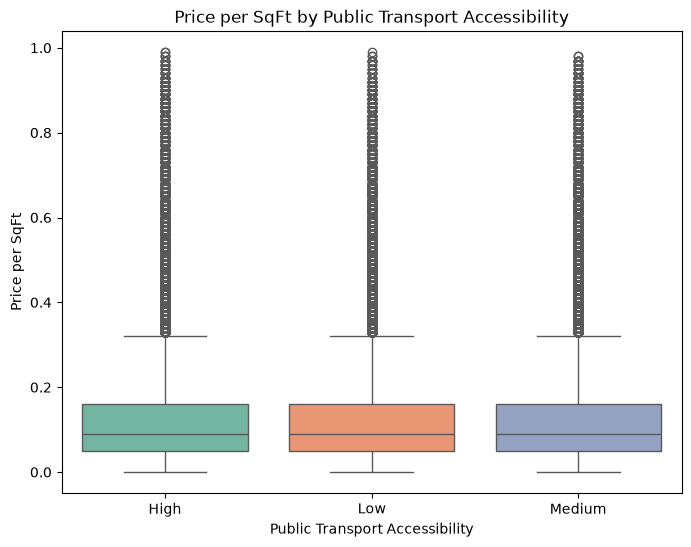

In [29]:
# 20.How does public transport accessibility relate to price per sq ft or investment potential?
from scipy.stats import f_oneway

groups = [df[df['Public_Transport_Accessibility']==cat]['Price_per_SqFt'].dropna()
          for cat in df['Public_Transport_Accessibility'].unique()]

f_stat, p_val = f_oneway(*groups)
print("F-statistic:", f_stat, "p-value:", p_val)

# Visualization of Price per SqFt by Public Transport Accessibility
plt.figure(figsize=(8,6))
sns.boxplot(x='Public_Transport_Accessibility', y='Price_per_SqFt', data=df, palette="Set2")
plt.title("Price per SqFt by Public Transport Accessibility")
plt.xlabel("Public Transport Accessibility")
plt.ylabel("Price per SqFt")
plt.show()

- F-statistic: 0.4268
- p-value: 0.6526
- Because 0.652 > 0.05, fail to reject the null hypothesis.

**Conclusion:** “The one-way ANOVA test indicates no statistically significant difference in property price per square foot across public transport accessibility levels (F = 0.43, p = 0.65). This suggests that accessibility to public transport does not have a measurable effect on property pricing or investment potential in this dataset.”

In [30]:
# set to skew becuse of highly right skewed 
df['Price_per_SqFt']=df['Price_per_SqFt']**(1/4)
df['Price_per_SqFt'].skew()

-0.21153974337729092

4.1 Regression

In [31]:
# Future price calculation
r = 0.05   # 5% annual growth across the pan India
t = 10     # 10 years
df['Future_Price'] = round(df['Price_in_Lakhs'] * ((1 + r) ** t),2)
df[['Price_in_Lakhs', 'Future_Price']].head()

,Price_in_Lakhs,Future_Price
0,489.76,797.77
1,195.52,318.48
2,183.79,299.37
3,300.29,489.14
4,182.90,297.92


In [32]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor

# 1. Define feature sets
numeric_features = ['Size_in_SqFt','BHK','Price_per_SqFt',
                    'Age_of_Property','Nearby_Schools','Nearby_Hospitals','Amenity_Count']

categorical_features = ['City','State','Property_Type','Furnished_Status',
                        'Availability_Status','Owner_Type','Facing']

# 2. Preprocessing
numeric_transformer = StandardScaler()
categorical_transformer = OneHotEncoder(drop='first', handle_unknown='ignore')

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)])

# 3. Linear Regression Pipeline (with scaling)
linreg_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LinearRegression())])

# 4. XGBoost Pipeline (no scaling needed)
xgb_pipeline = Pipeline(steps=[
    ('preprocessor', ColumnTransformer([
        ('num', 'passthrough', numeric_features),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_features)])),
    ('model', XGBRegressor(n_estimators=200, learning_rate=0.1, max_depth=6))])

# 5. Train/Test Split
X = df[numeric_features + categorical_features]
y = df['Future_Price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 6. Fit & Evaluate
# Linear Regression
linreg_pipeline.fit(X_train, y_train)
y_pred_lin = linreg_pipeline.predict(X_test)

print("Linear Regression:")
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_lin)))
print("MAE:", mean_absolute_error(y_test, y_pred_lin))
print("R²:", r2_score(y_test, y_pred_lin))

# XGBoost
xgb_pipeline.fit(X_train, y_train)
y_pred_xgb = xgb_pipeline.predict(X_test)

print("\nXGBoost:")
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_xgb)))
print("MAE:", mean_absolute_error(y_test, y_pred_xgb))
print("R²:", r2_score(y_test, y_pred_xgb))

# Cross-validation for XGBoost
scores = cross_val_score(xgb_pipeline, X, y, cv=5, scoring='r2')
print("XGB CV Score:", scores.mean())

Linear Regression:
RMSE: 108.62414752119398
MAE: 83.61212664731715
R²: 0.776930849649849

XGBoost:
RMSE: 14.47814616357384
MAE: 11.457359450184631
R²: 0.9960371040990723
XGB CV Score: 0.9960585955895949


#### Regression Conclusion
The regression task aimed to predict future property prices.

Linear Regression achieved moderate performance (R² ≈ 0.77, RMSE ≈ 108), showing that simple linear models cannot fully capture the complexity of real estate data.

XGBoost delivered excellent results (R² ≈ 0.996, RMSE ≈ 14), proving its ability to handle nonlinear relationships and categorical effects.

Conclusion: XGBoost is the most reliable regression model for property price forecasting, while Linear Regression serves as a baseline benchmark.

4.2 Classification

In [33]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from xgboost import XGBClassifier

# Rule: property price per SqFt <= locality median → good investment
df['Locality_Median_PPSF'] = df.groupby('Locality')['Price_per_SqFt'].transform('median')
df['Good_Investment'] = (df['Price_per_SqFt'] <= df['Locality_Median_PPSF']).astype(int)
numeric_features = ['Size_in_SqFt','BHK','Price_per_SqFt',
                    'Age_of_Property','Nearby_Schools','Nearby_Hospitals','Amenity_Count']

categorical_features = ['City','State','Property_Type','Furnished_Status',
                        'Availability_Status','Owner_Type','Facing']

X = df[numeric_features + categorical_features]
y = df['Good_Investment']

# Preprocessing
numeric_transformer = StandardScaler()
categorical_transformer = OneHotEncoder(drop='first', handle_unknown='ignore')

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)])

# Logistic Regression pipeline
logreg_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(max_iter=1000))])

# XGBoost pipeline
xgb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=6))])

# Train/Test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Fit & Evaluate Logistic Regression
logreg_pipeline.fit(X_train, y_train)
y_pred_log = logreg_pipeline.predict(X_test)
print("Logistic Regression:")
print("Accuracy:", accuracy_score(y_test, y_pred_log))
print("F1:", f1_score(y_test, y_pred_log))
print("ROC-AUC:", roc_auc_score(y_test, logreg_pipeline.predict_proba(X_test)[:,1]))

# Fit & Evaluate XGBoost
xgb_pipeline.fit(X_train, y_train)
y_pred_xgb = xgb_pipeline.predict(X_test)
print("\nXGBoost:")
print("Accuracy:", accuracy_score(y_test, y_pred_xgb))
print("F1:", f1_score(y_test, y_pred_xgb))
print("ROC-AUC:", roc_auc_score(y_test, xgb_pipeline.predict_proba(X_test)[:,1]))


Logistic Regression:
Accuracy: 0.98282
F1: 0.9835070944454044
ROC-AUC: 0.9985634780156316

XGBoost:
Accuracy: 0.9826
F1: 0.9833096727161109
ROC-AUC: 0.9985548840844576


##### Classification Conclusion
The classification task focused on predicting whether a property is a “Good Investment”.

Both Logistic Regression and XGBoost achieved very high accuracy (~98.3%) and ROC-AUC (~0.998), indicating strong separation between good and poor investments.

Logistic Regression provides interpretability (coefficients show direct feature influence), while XGBoost offers robustness and scalability.

Conclusion: Both models are effective, but XGBoost is preferred for production deployment due to its consistency across regression and classification tasks.

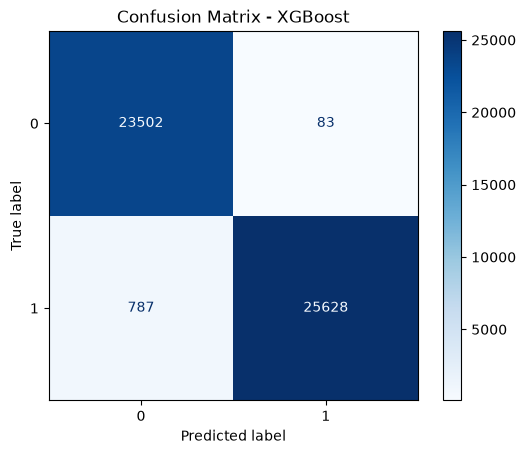

In [ ]:
# visually showing confusion matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
# Example for XGBoost predictions
cm = confusion_matrix(y_test, y_pred_xgb)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Blues")
plt.title("Confusion Matrix - XGBoost")
plt.show()

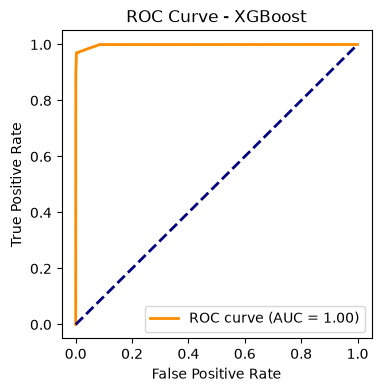

In [ ]:
# visually showing ROC curve
from sklearn.metrics import roc_curve, auc
# Get probabilities for positive class
y_prob_xgb = xgb_pipeline.predict_proba(X_test)[:,1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob_xgb)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(4,4))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (AUC = %0.2f)' % roc_auc)
plt.plot([0,1],[0,1], color='navy', lw=2, linestyle='--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - XGBoost")
plt.legend(loc="lower right")
plt.show()

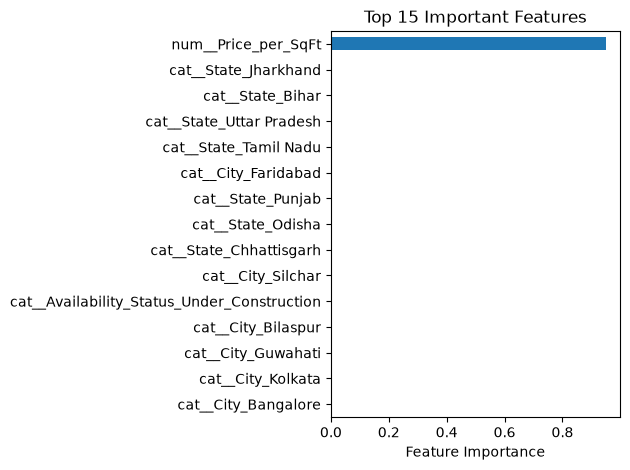

In [ ]:
# Add feature importance
import matplotlib.pyplot as plt

xgb_model = xgb_pipeline.named_steps["model"]
feature_names = xgb_pipeline.named_steps["preprocessor"].get_feature_names_out()

importance = pd.Series(
    xgb_model.feature_importances_,
    index=feature_names).sort_values(ascending=False)

importance.head(15).sort_values().plot(kind="barh", title="Top 15 Important Features")

plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()